<img src = "https://drive.google.com/uc?export=view&id=1Md0grlXXV4fB0bkYuMWzBiS64RvjaFGX" alt = "Encabezado MLDS" width = "100%">  </img>

# Clasificación visual de residuos con aprendizaje profundo
## Fase 1 · Entendimiento del negocio y carga de datos

**Proyecto aplicado · Módulo 5 · Machine Learning & Data Science**  
**Universidad Nacional de Colombia**  
**Fecha de la propuesta:** 13 de octubre de 2026 · **Horizonte:** cierre en la fase 5, con la entrega final del módulo

| Integrante | Nombre |
|---|---|
| 1 | Juan Carlos Andrade Unigarro |
| 2 | Natalia Patricia Remolina Rodriguez |

**Propuesta:** evaluar un prototipo que sugiera la categoría de un residuo aislado a partir de una fotografía, como apoyo a una estación educativa de separación. Se compararán una CNN pequeña y MobileNetV2 con transferencia de aprendizaje.

**Estado de esta entrega:** fuentes investigadas, datos descargados, calidad revisada y particiones preparadas. Los resultados mostrados corresponden a la auditoría de datos; el entrenamiento y las métricas predictivas se desarrollarán en las fases siguientes.

## 1. Selección y justificación del proyecto

Se reevaluaron las alternativas con cuatro criterios: relación directa con Deep Learning, datos etiquetados disponibles, facilidad de ejecución en Colab y alcance defendible dentro de las cinco fases del proyecto. La siguiente comparación es un juicio de planeación; los tamaños provienen de las fuentes y no son resultados de entrenamiento.

| Alternativa | Datos documentados | Ventaja | Riesgo para el plazo | Decisión |
|---|---|---|---|---|
| Residuos · TrashNet [1–2] | 2.527 imágenes; 6 categorías | Problema visual concreto, descarga reducida y comparación de CNN | Fondos controlados, desbalance y etiquetas que deben auditarse | **Seleccionado con alcance de imagen individual** |
| Hojas de fríjol · Beans [4] | 1.295 imágenes; 3 categorías | Particiones oficiales y tarea pequeña | Evidencia limitada para generalizar a otros cultivos o regiones | Alternativa viable si el equipo prioriza agricultura |
| Solicitudes bancarias · BANKING77 [5] | 13.083 consultas; 77 intenciones | Aplicación clara en soporte | Inglés e intenciones muy parecidas; acotar categorías cambia el problema | Viable, con más trabajo de definición semántica |
| Mensajes spam · UCI [6] | Aproximadamente 5.500 mensajes; 2 categorías | Carga sencilla y costo computacional bajo | Menor riqueza visual; una línea base clásica puede ser competitiva | Alternativa sencilla, menos alineada con el objetivo de comparar CNN |

**Razón de la elección.** TrashNet ofrece un equilibrio entre utilidad, contenido del módulo y alcance: seis clases permiten un análisis por categoría comprensible; su versión reducida evita descargar las fotografías originales; y una demostración completa cabe dentro de un notebook. Beans requiere menos categorías, pero TrashNet permite analizar más confusiones de materiales y tiene más imágenes. La selección no supone que TrashNet represente los residuos de una ciudad o institución colombiana.

**Mejora respecto de una propuesta genérica:** la comparación se apoya en una auditoría reproducible, conserva el origen de cada archivo, identifica conflictos de etiquetas y controla la separación de imágenes similares. Esto permite discutir la confiabilidad del experimento además de su exactitud.

## 2. Entendimiento del negocio

### 2.1 Contexto investigado

El informe *Global Waste Management Outlook 2024* del Programa de las Naciones Unidas para el Medio Ambiente y la ISWA proyecta que los residuos sólidos municipales podrían alcanzar 3.800 millones de toneladas anuales en 2050 [3]. Esta referencia justifica estudiar herramientas que apoyen el aprendizaje sobre materiales y separación; no demuestra por sí sola la necesidad ni el impacto de este prototipo en una institución particular.

### 2.2 Escenario y problema delimitado

Se plantea una **estación educativa de separación en un campus**, como escenario hipotético de aplicación. Un participante presenta un residuo aislado ante una cámara o carga su fotografía. El orientador necesita reconocer su categoría visual y explicar cuándo una imagen resulta ambigua. Materiales de apariencia similar, envases compuestos y diferencias de iluminación pueden dificultar esa identificación.

La oportunidad consiste en evaluar si un clasificador ofrece sugerencias útiles para esa actividad. No se dispone de mediciones del tiempo actual de atención, volumen de usuarios o errores de separación en un campus real. Esas variables requerirían un piloto posterior y no se presentarán como beneficios ya obtenidos.

### 2.3 Actores, decisión y valor esperado

| Actor | Necesidad o decisión | Aporte esperado del prototipo |
|---|---|---|
| Participante | Reconocer la categoría visual del objeto fotografiado | Ver una sugerencia y ejemplos de confusiones frecuentes |
| Orientador ambiental | Revisar la sugerencia y explicar la clasificación | Contar con una ayuda visual y conocer sus límites por clase |
| Equipo del proyecto | Decidir si el modelo merece una validación más amplia | Comparar calidad, errores y costo de ejecución de dos alternativas |

**Objetivo del negocio:** apoyar la identificación preliminar de residuos en una actividad educativa mediante sugerencias revisables por un orientador. La fase académica evaluará la calidad de esa sugerencia; una reducción real de contaminación de materiales o de tiempo de atención queda como hipótesis para un piloto.

**Unidad de análisis:** una fotografía de un objeto aislado.  
**Decisión asistida:** asignar una de las seis etiquetas de TrashNet.  
**Límite semántico:** la clase `trash` es una etiqueta del dataset, no una categoría universal que reconozca cualquier objeto desconocido. Identificar un material tampoco determina automáticamente su reciclabilidad o su ruta local de disposición.

## 3. Objetivos y criterios de éxito

### 3.1 Objetivo general del proyecto

Desarrollar y evaluar, al cierre del módulo (fase 5), un prototipo reproducible en Google Colab que clasifique imágenes individuales de residuos en seis categorías, comparando una CNN pequeña entrenada desde cero con MobileNetV2 adaptada mediante transferencia de aprendizaje, utilizando datos auditados y una prueba final independiente de los ajustes de modelos.

### 3.2 Objetivos específicos

| Objetivo | Evidencia verificable | Fase |
|---|---|---|
| Investigar el problema y delimitar el uso | Contexto con fuentes, actores, alcance y limitaciones | Fase 1 |
| Obtener y auditar el dataset | Descarga verificable; conteos, imágenes legibles y reporte de duplicados | Fase 1 |
| Preparar un protocolo reproducible | Manifiesto de imágenes, exclusiones y particiones con semilla fija | Fases 1–2 |
| Entrenar y comparar dos enfoques | Configuración, curvas de aprendizaje y resultados de validación | Fases 3–4 |
| Evaluar errores y viabilidad del prototipo | F1 macro, recall por clase, matriz de confusión, tiempo y demostración | Fase 5 |

### 3.3 Criterios de éxito propuestos

- **Entrega técnica:** ejecutar el notebook completo, reproducir los datos y documentar el experimento y sus decisiones.
- **Meta predictiva del proyecto:** F1 macro de prueba ≥ 0,80 y recall ≥ 0,60 en cada categoría, junto con una comparación frente a una línea base mayoritaria. Son metas de trabajo definidas antes de entrenar, no resultados obtenidos ni umbrales establecidos por el curso.
- **Selección:** elegir arquitectura y configuración únicamente con validación. La prueba se usará al final para estimar el desempeño de las configuraciones ya fijadas.
- **Utilidad demostrable:** cargar una imagen compatible con el alcance y mostrar categoría, puntuaciones del modelo y limitaciones. Las puntuaciones softmax no se presentarán como probabilidades calibradas.

Si las metas no se alcanzan, se conservarán los resultados y se explicarán las causas; no se modificarán retrospectivamente las metas ni se ajustará el modelo a la prueba. El cumplimiento académico depende también de la calidad del método y de la argumentación.

## 4. Alcance y entregables

**Alcance incluido:** clasificación supervisada de imágenes RGB de un residuo aislado, seis etiquetas originales, auditoría de calidad, dos modelos, evaluación por clase y demostración dentro de Colab. Las imágenes de entrada deberán aproximarse a las condiciones del dataset: objeto visible y fondo sencillo.

| Fase oficial | Contenido |
|---|---|
| 1 · Entendimiento del negocio y carga de datos (actual) | Negocio, elección de datos, carga ejecutada, auditoría de calidad, particiones y plan |
| 2 · Entendimiento y preparación de los datos | Exploración del conjunto de entrenamiento, pipeline de imágenes (redimensionado, escala y aumentos), pesos por clase y línea base mayoritaria |
| 3 · Diseño e implementación | Arquitecturas de la CNN pequeña y de MobileNetV2 con nueva cabeza; ensayo corto para medir tiempos |
| 4 · Entrenamiento y validación | Entrenamiento de ambos modelos, curvas de aprendizaje, ajustes limitados con validación y elección justificada |
| 5 · Evaluación y entrega final | Evaluación única en prueba, análisis de errores, conclusiones, modelo guardado y demostración en el notebook |

La detección de varios objetos, la segmentación, el video continuo, una aplicación desplegada, la integración con robots y la recomendación normativa de disposición quedan fuera del alcance del proyecto. Una pequeña prueba con fotografías externas sería una extensión exploratoria, después de asegurar el entregable principal, y no sustituiría la prueba reservada.

## 5. Planeación por fases

La planeación sigue las cinco fases oficiales del proyecto aplicado. Cada fase se cierra con un notebook ejecutado que reutiliza las particiones fijadas en esta entrega. Las fechas son la propuesta del equipo para cerrar el proyecto hacia el 7 de noviembre de 2026 y se ajustarán si el calendario de la plataforma indica otras.

| Fase | Fecha límite | Actividades | Entregable / condición de cierre | Responsable | Esfuerzo del equipo* |
|---|---|---|---|---|---:|
| 1 · Negocio y carga de datos (actual) | Dom 18-oct | Selección del problema, contexto, descarga verificada y auditoría | Notebook de fase 1 ejecutado; datos, riesgos y plan documentados | A + B | 6 h |
| 2 · Entendimiento y preparación de los datos | Jue 22-oct | Exploración del conjunto de entrenamiento, pipeline de imágenes, aumentos, pesos por clase y línea base | Pipeline reproducible y métricas de la línea base en validación | A (lidera) + B | 6 h |
| 3 · Diseño e implementación | Mar 27-oct | Implementar la CNN pequeña y MobileNetV2 con nueva cabeza; ensayo corto de tiempo | Ambos modelos compilados y probados con un lote; tiempo por época medido | B (lidera) + A | 8 h |
| 4 · Entrenamiento y validación | Dom 1-nov | Entrenar ambos modelos con parada temprana; ajustes limitados usando validación | Curvas, tabla de resultados en validación y configuración final elegida | B (lidera) + A | 10 h |
| 5 · Evaluación y entrega final | Sáb 7-nov | Evaluar una sola vez en prueba, analizar errores, preparar demostración, conclusiones y presentación | Notebook final reproducible, modelo guardado, demostración y presentación final (semana del 2 al 7 de noviembre) | A + B | 9 h |

*Estimación de planeación: 39 horas-persona en total, aproximadamente 19,5 por integrante. Debe confirmarse con la disponibilidad del equipo; no representa tiempo ya invertido ni duración medida de entrenamiento.*

**Distribución de trabajo:** el equipo tiene dos integrantes. **A · Juan Carlos Andrade Unigarro:** datos, trazabilidad y evaluación. **B · Natalia Patricia Remolina Rodriguez:** implementación de modelos y experimentos. La documentación es compartida; cada integrante revisa las secciones desarrolladas por el otro y conoce el notebook completo.

**Recursos:** Colab, Python, almacenamiento para aproximadamente 43 MB comprimidos más archivos extraídos y salidas; GPU cuando esté disponible para modelado. Esta fase usa CPU. Se fija como presupuesto inicial un máximo de seis ejecuciones de entrenamiento, incluyendo las dos configuraciones base; un ensayo corto medirá el tiempo real antes de ampliar experimentos. Guardar modelos y registros después de cada ejecución evita perder el avance ante reinicios. Colab no garantiza un tipo de GPU ni disponibilidad constante [9].

| Riesgo | Señal / impacto | Acción y responsable |
|---|---|---|
| Conflictos de etiquetas o duplicados | Métricas poco confiables | Auditar hashes, apartar conflictos y conservar el registro · A |
| Imágenes similares entre particiones | Evaluación demasiado optimista | Agrupar candidatos visuales antes de dividir · A |
| Pocas imágenes en `trash` | Resultado global oculta errores | F1 macro, recall por clase y pesos calculados solo en entrenamiento · A + B |
| Sobreajuste o GPU limitada | Curvas divergentes o ejecución lenta | Modelo pequeño, parada temprana y extractor preentrenado congelado · B |
| Fondos nuevos o materiales compuestos | Fallos fuera del dominio | Declarar el dominio y analizar errores; piloto externo como trabajo futuro · A |
| Falta de tiempo | Retraso al cerrar la fase 4 | Priorizar dos configuraciones base y su evaluación; cerrar ajustes adicionales · Equipo |

## 6. Fuente y diccionario de datos

Se utiliza **TrashNet**, publicado por Gary Thung y Mindy Yang [1], descargado desde el repositorio del autor en Hugging Face [2]. El repositorio informa que las fotografías se tomaron con teléfonos, sobre una cartulina blanca y con iluminación natural o de interiores. La tarjeta del dataset declara licencia MIT; se conserva la atribución a los autores y los enlaces de origen.

| Propiedad | Valor |
|---|---|
| Archivo usado | `dataset-resized.zip` |
| Revisión fijada | `94cd17ebfd6702bf62281d3c89f22ff649815b46` |
| Cantidad documentada | 2.527 imágenes |
| Resolución documentada | 512 × 384 píxeles |
| Tipo de problema | Clasificación multiclase, una etiqueta por imagen |
| Variable de entrada | Contenido RGB de la fotografía |
| Variable objetivo | Nombre de la carpeta de categoría |
| Particiones originales | El ZIP seleccionado no proporciona una partición oficial para este experimento |

| Etiqueta original | Interpretación en este proyecto | Cantidad documentada |
|---|---|---:|
| `cardboard` | Cartón | 403 |
| `glass` | Vidrio | 501 |
| `metal` | Metal | 410 |
| `paper` | Papel | 594 |
| `plastic` | Plástico | 482 |
| `trash` | Basura residual según la etiqueta de TrashNet | 137 |

Las cantidades se comprobarán con los archivos descargados. El identificador relativo, dimensiones, tamaño, formato y hashes son metadatos de control; no serán variables predictoras. No hay identificador del objeto físico, lugar o sesión de captura que permita garantizar independencia por objeto o por sitio.

## 7. Entorno y adquisición reproducible

Se emplean bibliotecas habituales de Colab. La descarga fija una revisión y verifica SHA-256 para confirmar que el ZIP coincide con el auditado en esta entrega. Una descarga incompleta se elimina y genera un error explícito. La caché evita descargar de nuevo un archivo válido. Solo se extraen las imágenes de las categorías esperadas; los metadatos de macOS no forman parte de los datos.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib.metadata as metadata
import json
import platform
import shutil
import time
import urllib.request
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.fft import dctn
from sklearn.model_selection import StratifiedGroupKFold
from IPython.display import display, Markdown

SEED = 42
REVISION = "94cd17ebfd6702bf62281d3c89f22ff649815b46"
DATA_URL = f"https://huggingface.co/datasets/garythung/trashnet/resolve/{REVISION}/dataset-resized.zip"
EXPECTED_SHA256 = "c060e8abfe5d6de0578ca15be1ed8ad0794a865d333c3473d53d1d9ad6e38b8c"
EXPECTED = {"cardboard": 403, "glass": 501, "metal": 410,
            "paper": 594, "plastic": 482, "trash": 137}
CLASSES = list(EXPECTED)
LABEL_ES = dict(zip(CLASSES, ["Cartón", "Vidrio", "Metal", "Papel", "Plástico", "Residual"]))
ROOT = Path.cwd() / "residuos_fase1"
ROOT.mkdir(parents=True, exist_ok=True)
ARCHIVE = ROOT / "dataset-resized.zip"
DATA_DIR = ROOT / "imagenes"
REPORT_DIR = ROOT / "reportes"
DATA_DIR.mkdir(exist_ok=True)
REPORT_DIR.mkdir(exist_ok=True)

def miles(n):
    """Formatea enteros con punto como separador de miles."""
    return f"{n:,}".replace(",", ".")


plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
versions = {p: metadata.version(p) for p in
            ["numpy", "pandas", "Pillow", "scipy", "scikit-learn", "matplotlib"]}
print("Python:", platform.python_version(), "| Semilla:", SEED)
display(pd.Series(versions, name="versión").to_frame())

Python: 3.13.16 | Semilla: 42


,versión
numpy,2.1.3
pandas,2.2.3
Pillow,11.3.0
scipy,1.16.3
scikit-learn,1.6.1
matplotlib,3.10.0


In [2]:
def sha256_file(path):
    """Calcula el hash por bloques para mantener bajo el uso de memoria."""
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def obtain_archive(url, destination, expected_hash):
    """Reutiliza una caché válida o descarga y verifica antes de reemplazarla."""
    if destination.exists() and sha256_file(destination) == expected_hash:
        return "caché verificada"
    temporary = destination.with_suffix(".download")
    try:
        with urllib.request.urlopen(url, timeout=60) as response, temporary.open("wb") as target:
            shutil.copyfileobj(response, target, length=1024 * 1024)
        if sha256_file(temporary) != expected_hash:
            raise ValueError("El SHA-256 no coincide con la versión auditada.")
        temporary.replace(destination)
    except Exception as exc:
        temporary.unlink(missing_ok=True)
        raise RuntimeError("No se pudo obtener un ZIP válido. Revise la conexión y ejecute de nuevo.") from exc
    return "descarga verificada"


t0 = time.perf_counter()
acquisition_status = obtain_archive(DATA_URL, ARCHIVE, EXPECTED_SHA256)
manifest_names = []
with zipfile.ZipFile(ARCHIVE) as archive:
    for member in archive.infolist():
        parts = Path(member.filename).parts
        if (len(parts) == 3 and parts[0] == "dataset-resized"
                and parts[1] in CLASSES and parts[2].lower().endswith(".jpg")):
            relative = Path(parts[1]) / parts[2]
            target = DATA_DIR / relative
            target.parent.mkdir(exist_ok=True)
            with archive.open(member) as source, target.open("wb") as destination:
                shutil.copyfileobj(source, destination)
            manifest_names.append(relative.as_posix())

manifest_names = sorted(manifest_names)
assert len(manifest_names) == len(set(manifest_names)), "Rutas duplicadas dentro del ZIP."
print("Adquisición:", acquisition_status)
print("ZIP:", f"{ARCHIVE.stat().st_size / 1_000_000:.2f} MB")
print("SHA-256:", sha256_file(ARCHIVE))
print("Imágenes extraídas:", len(manifest_names))
print("Tiempo de adquisición/extracción:", f"{time.perf_counter() - t0:.1f} s")

Adquisición: descarga verificada
ZIP: 42.83 MB
SHA-256: c060e8abfe5d6de0578ca15be1ed8ad0794a865d333c3473d53d1d9ad6e38b8c
Imágenes extraídas: 2527
Tiempo de adquisición/extracción: 5.3 s


## 8. Auditoría de cantidad, integridad y contenido

Se intenta decodificar **cada imagen**, no solo abrir el nombre del archivo. Se revisan etiquetas, formatos, tamaños y valores ausentes. Se calculan dos hashes exactos: uno de los bytes originales y otro de los píxeles RGB junto con sus dimensiones. El segundo identifica copias visualmente idénticas aunque sus metadatos de archivo difieran.

Como control adicional se calcula un hash perceptual de 64 bits a partir de componentes de baja frecuencia. Una distancia de Hamming pequeña identifica **candidatos a revisión**, no demuestra identidad de objeto ni equivalencia de etiqueta. Este control se aplica exclusivamente para revisar similitud y organizar particiones; no es el modelo de clasificación.

In [3]:
def perceptual_hash(rgb):
    """Huella de baja frecuencia: DCT 32×32, bloque 8×8 y umbral mediano."""
    gray = np.asarray(rgb.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
    low_frequency = dctn(gray, type=2, norm="ortho")[:8, :8].ravel()
    bits = low_frequency > np.median(low_frequency[1:])
    bits[0] = False  # El componente DC no participa en la comparación.
    return int.from_bytes(np.packbits(bits).tobytes(), "big")


records = []
t0 = time.perf_counter()
for relative in manifest_names:
    path = DATA_DIR / relative
    row = {"ruta": relative, "clase": path.parent.name,
           "bytes": path.stat().st_size, "error": ""}
    try:
        with Image.open(path) as image:
            image.load()
            rgb = image.convert("RGB")
            row.update(ancho=image.width, alto=image.height, modo=image.mode, formato=image.format,
                       sha256=sha256_file(path),
                       pixel_sha256=hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest(),
                       phash=f"{perceptual_hash(rgb):016x}")
    except Exception as exc:
        row["error"] = f"{type(exc).__name__}: {exc}"
    records.append(row)

raw = pd.DataFrame(records).sort_values("ruta").reset_index(drop=True)
valid = raw.loc[raw["error"].eq("")].copy()
counts = raw["clase"].value_counts().reindex(CLASSES, fill_value=0)
inventory = pd.DataFrame({"documentadas": pd.Series(EXPECTED), "cargadas": counts})
inventory["diferencia"] = inventory["cargadas"] - inventory["documentadas"]
inventory["porcentaje"] = (100 * inventory["cargadas"] / len(raw)).round(2)
display(inventory)
print("Archivos no decodificables:", int(raw["error"].ne("").sum()))
print("Etiquetas vacías:", int(raw["clase"].isna().sum()))
print("Metadatos ausentes en imágenes válidas:", int(valid.isna().sum().sum()))
print("Formatos:", valid["formato"].value_counts().to_dict())
print("Modos:", valid["modo"].value_counts().to_dict())
print("Dimensiones:", valid.groupby(["ancho", "alto"]).size().to_dict())
print("Auditoría completa:", f"{time.perf_counter() - t0:.1f} s")

,documentadas,cargadas,diferencia,porcentaje
cardboard,403,403,0,15.95
glass,501,501,0,19.83
metal,410,410,0,16.22
paper,594,594,0,23.51
plastic,482,482,0,19.07
trash,137,137,0,5.42


Archivos no decodificables: 0
Etiquetas vacías: 0
Metadatos ausentes en imágenes válidas: 0
Formatos: {'JPEG': 2527}
Modos: {'RGB': 2527}
Dimensiones: {(512, 384): 2527}
Auditoría completa: 20.0 s


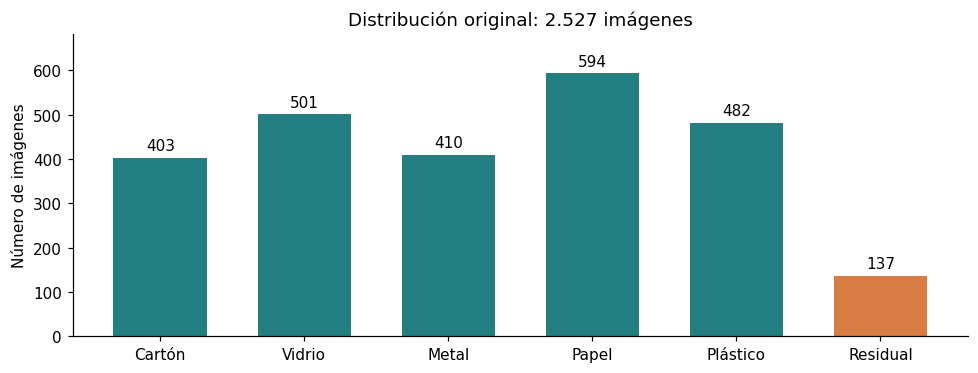

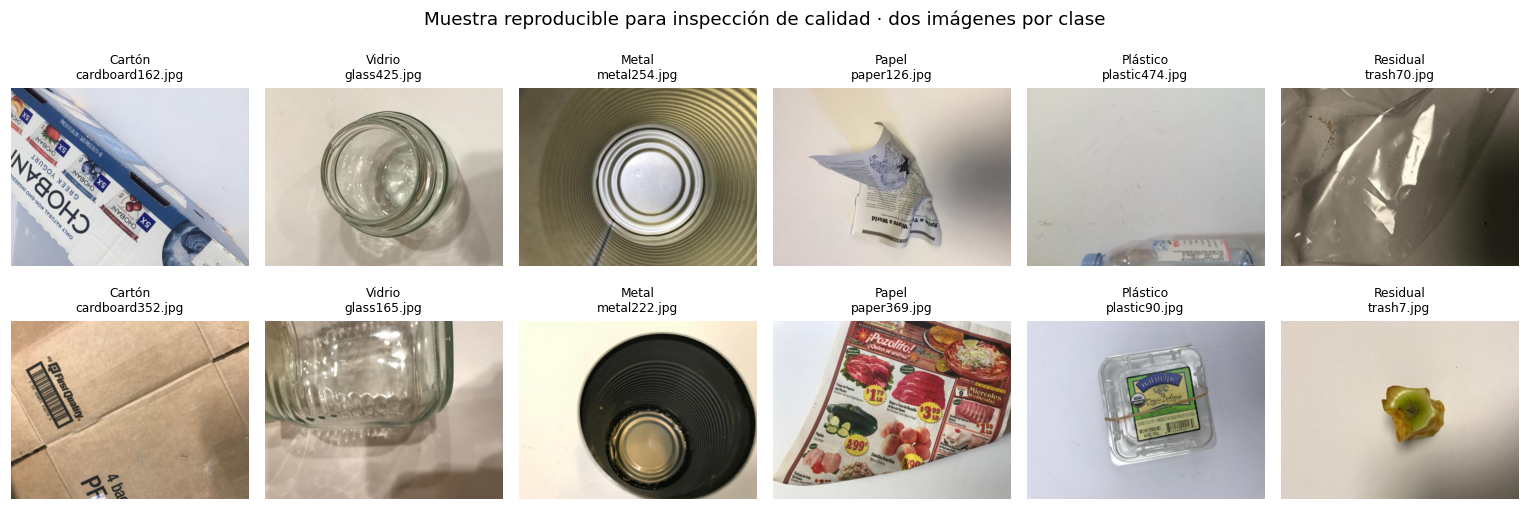

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
colors = ["#247f83"] * len(CLASSES)
colors[CLASSES.index("trash")] = "#d77c42"
bars = ax.bar([LABEL_ES[c] for c in CLASSES], counts.values, color=colors, width=0.65)
ax.bar_label(bars, padding=3)
ax.set(title=f"Distribución original: {miles(len(raw))} imágenes", ylabel="Número de imágenes")
ax.set_ylim(0, counts.max() * 1.15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for col, label in enumerate(CLASSES):
    examples = valid.loc[valid["clase"].eq(label)].sample(2, random_state=SEED)
    for row, (_, example) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / example["ruta"]) as picture:
            axes[row, col].imshow(picture)
        axes[row, col].set_title(f"{LABEL_ES[label]}\n{Path(example['ruta']).name}", fontsize=8)
        axes[row, col].axis("off")
fig.suptitle("Muestra reproducible para inspección de calidad · dos imágenes por clase", fontsize=12)
fig.tight_layout()
plt.show()

In [5]:
ratio = counts.max() / counts.min()
majority_share = counts.max() / counts.sum()
display(Markdown(
    f"**Lectura de los datos.** Se cargaron {miles(len(raw))} imágenes, de las cuales "
    f"{miles(len(valid))} se decodifican correctamente. La clase mayoritaria es `{counts.idxmax()}` "
    f"({counts.max()} imágenes) y la minoritaria es `{counts.idxmin()}` ({counts.min()}). "
    f"La relación entre ambas es {ratio:.2f}:1. Predecir siempre la clase mayoritaria acertaría "
    f"aproximadamente el {majority_share:.1%} en esta distribución original, sin demostrar aprendizaje. "
    "Por eso se propone F1 macro y resultados por clase. La colección permite un experimento "
    "académico acotado, pero el tamaño y el dominio de captura limitan su representatividad."
))

**Lectura de los datos.** Se cargaron 2.527 imágenes, de las cuales 2.527 se decodifican correctamente. La clase mayoritaria es `paper` (594 imágenes) y la minoritaria es `trash` (137). La relación entre ambas es 4.34:1. Predecir siempre la clase mayoritaria acertaría aproximadamente el 23.5% en esta distribución original, sin demostrar aprendizaje. Por eso se propone F1 macro y resultados por clase. La colección permite un experimento académico acotado, pero el tamaño y el dominio de captura limitan su representatividad.

**Observación visual adicional:** la muestra incluye una imagen con el objeto parcialmente fuera del encuadre (`plastic474.jpg`). La decodificación correcta no garantiza que una imagen sea informativa. Se conserva su etiqueta y se documenta este tipo de limitación para el análisis de errores; no se descartan imágenes por su apariencia de forma automática.

## 9. Duplicados, conflictos de etiquetas y decisiones de calidad

Se aplica una política fijada antes del entrenamiento:

1. **Archivos ilegibles:** apartarlos y registrar el motivo.
2. **Píxeles idénticos con etiquetas diferentes:** apartar todas las copias del conflicto, sin adivinar la etiqueta correcta ni modificar la fuente.
3. **Copias exactas con la misma etiqueta:** conservar una sola, de forma determinista.
4. **Similitud perceptual:** conservar las imágenes y agrupar los candidatos para que permanezcan en una misma partición. No cambiar etiquetas ni declarar duplicados exactos por esta heurística.

Estas decisiones mantienen intacto el dataset descargado; la exclusión se registra en un manifiesto de trabajo.

Copias adicionales exactas por bytes: 3
Grupos de píxeles idénticos con etiquetas incompatibles: 3
Archivos involucrados en conflictos: 6


,ruta,clase,sha256
0,glass/glass115.jpg,glass,81546d1362d75fc60718e5852593c58f66f813e8c1e9d1...
1,glass/glass176.jpg,glass,c41b99aec8a3257c8668a2144ebbaf8042018f0a85d88e...
2,glass/glass389.jpg,glass,e971f4f8f50e960e454ea724cec922fc2988bbf4027aa4...
3,metal/metal91.jpg,metal,81546d1362d75fc60718e5852593c58f66f813e8c1e9d1...
4,plastic/plastic152.jpg,plastic,c41b99aec8a3257c8668a2144ebbaf8042018f0a85d88e...
5,plastic/plastic332.jpg,plastic,e971f4f8f50e960e454ea724cec922fc2988bbf4027aa4...


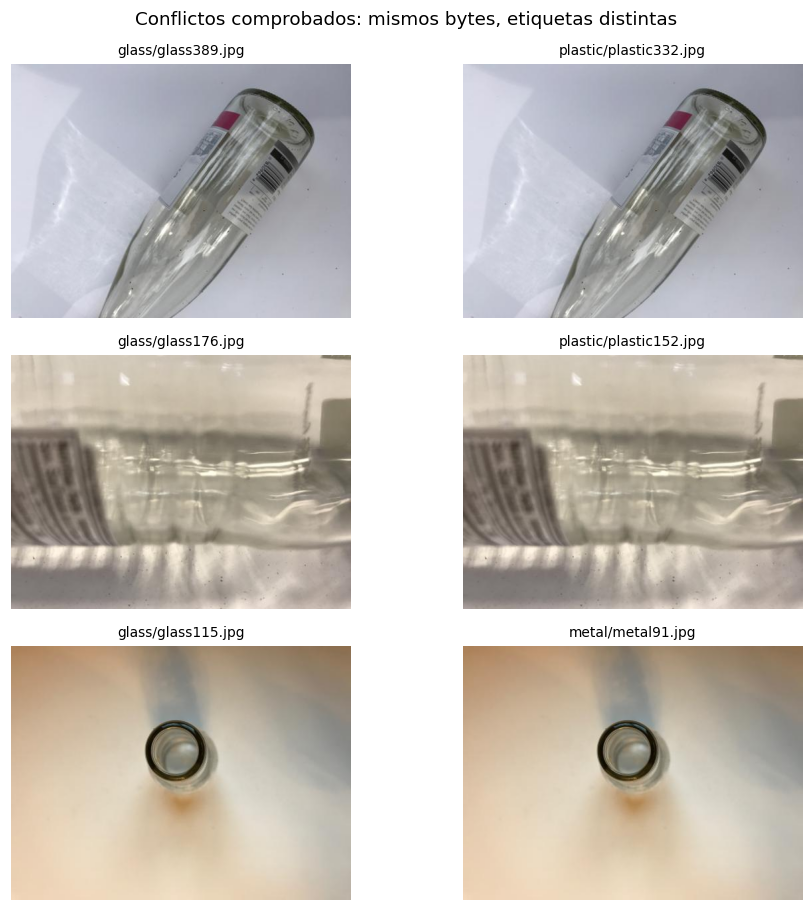

In [6]:
exact_byte_rows = valid.loc[valid["sha256"].duplicated(keep=False)]
label_counts_by_hash = valid.groupby("pixel_sha256")["clase"].nunique()
conflict_hashes = set(label_counts_by_hash[label_counts_by_hash > 1].index)
conflicts = valid.loc[valid["pixel_sha256"].isin(conflict_hashes)].copy()

print("Copias adicionales exactas por bytes:", int(valid["sha256"].duplicated().sum()))
print("Grupos de píxeles idénticos con etiquetas incompatibles:", len(conflict_hashes))
print("Archivos involucrados en conflictos:", len(conflicts))
display(conflicts[["ruta", "clase", "sha256"]].reset_index(drop=True))

if len(conflict_hashes):
    groups = list(conflicts.groupby("pixel_sha256", sort=True))
    fig, axes = plt.subplots(len(groups), 2, figsize=(9, 2.8 * len(groups)), squeeze=False)
    for row, (_, group) in enumerate(groups):
        for col, (_, item) in enumerate(group.head(2).iterrows()):
            with Image.open(DATA_DIR / item["ruta"]) as picture:
                axes[row, col].imshow(picture)
            axes[row, col].set_title(item["ruta"], fontsize=9)
            axes[row, col].axis("off")
    fig.suptitle("Conflictos comprobados: mismos bytes, etiquetas distintas", fontsize=12)
    fig.tight_layout()
    plt.show()

In [7]:
PHASH_THRESHOLD = 4  # Filtro conservador de candidatos; no implica identidad.
items = valid[["ruta", "clase", "phash"]].to_dict("records")
hash_values = [int(item["phash"], 16) for item in items]
pairs = []
for i, left_hash in enumerate(hash_values):
    for j in range(i + 1, len(hash_values)):
        distance = (left_hash ^ hash_values[j]).bit_count()
        if distance <= PHASH_THRESHOLD:
            pairs.append({"ruta_a": items[i]["ruta"], "ruta_b": items[j]["ruta"],
                          "clase_a": items[i]["clase"], "clase_b": items[j]["clase"],
                          "distancia": distance})
similar = pd.DataFrame(pairs, columns=["ruta_a", "ruta_b", "clase_a", "clase_b", "distancia"])
print("Pares candidatos en la colección original:", len(similar))
display(similar.head(12))

Pares candidatos en la colección original: 28


,ruta_a,ruta_b,clase_a,clase_b,distancia
0,cardboard/cardboard15.jpg,cardboard/cardboard361.jpg,cardboard,cardboard,2
1,cardboard/cardboard386.jpg,cardboard/cardboard72.jpg,cardboard,cardboard,2
2,glass/glass115.jpg,metal/metal91.jpg,glass,metal,0
3,glass/glass176.jpg,plastic/plastic152.jpg,glass,plastic,0
4,glass/glass389.jpg,plastic/plastic332.jpg,glass,plastic,0
5,metal/metal120.jpg,metal/metal50.jpg,metal,metal,4
6,metal/metal154.jpg,plastic/plastic10.jpg,metal,plastic,4
7,metal/metal155.jpg,metal/metal6.jpg,metal,metal,2
8,metal/metal159.jpg,plastic/plastic11.jpg,metal,plastic,2
9,paper/paper101.jpg,paper/paper108.jpg,paper,paper,2


**Interpretación de la revisión visual.** Se comprobaron tres pares de archivos idénticos, cada uno con etiquetas distintas: `glass115/metal91`, `glass176/plastic152` y `glass389/plastic332`. Se apartan sus seis archivos. No se relabelan a partir de una interpretación visual.

La similitud perceptual también genera falsos positivos: `metal154` y `plastic10`, por ejemplo, tienen una composición parecida pero representan objetos diferentes. Por ello, una distancia pequeña no elimina imágenes ni modifica su clase. Agrupar candidatos es una precaución conservadora para la partición. Esta heurística puede omitir fotografías del mismo objeto con cambios importantes de ángulo; no sustituye un identificador de objeto físico que el dataset no proporciona.

In [8]:
eligible = valid.loc[~valid["pixel_sha256"].isin(conflict_hashes)].copy()
same_label_duplicates = eligible.loc[eligible["pixel_sha256"].duplicated(keep="first")]
usable = eligible.drop_duplicates("pixel_sha256", keep="first").copy().reset_index(drop=True)

raw["estado"] = "utilizable"
raw.loc[raw["error"].ne(""), "estado"] = "ilegible"
raw.loc[raw["pixel_sha256"].isin(conflict_hashes), "estado"] = "conflicto_etiqueta"
raw.loc[raw["ruta"].isin(same_label_duplicates["ruta"]), "estado"] = "duplicado_misma_etiqueta"
print("Estado final de la auditoría:")
display(raw["estado"].value_counts().rename_axis("estado").to_frame("imágenes"))
print("Imágenes utilizables para modelado:", len(usable))
display(pd.DataFrame({"original": counts,
                      "utilizable": usable["clase"].value_counts().reindex(CLASSES, fill_value=0)}))

Estado final de la auditoría:


,imágenes
estado,
utilizable,2521
conflicto_etiqueta,6


Imágenes utilizables para modelado: 2521


,original,utilizable
clase,,
cardboard,403,403
glass,501,498
metal,410,409
paper,594,594
plastic,482,480
trash,137,137


## 10. Particiones preparadas sin cruces de grupos similares

Se crean grupos por componentes conectados entre candidatos perceptualmente similares. Un grupo puede contener distintas etiquetas, porque la agrupación no es una corrección semántica. Después se usa una partición estratificada por clase y restringida por grupo, con semilla 42.

Para aproximar **70% entrenamiento, 15% validación y 15% prueba**, se generan 20 pliegues y se asignan 14, 3 y 3, respectivamente. El porcentaje puede variar levemente por la restricción de grupos. El manifiesto guarda la asignación exacta para reutilizarla en ambas arquitecturas.

La revisión global anterior fue una auditoría de datos previa al entrenamiento. A partir de esta partición, la prueba queda reservada para la evaluación final: no se utilizará para seleccionar arquitectura, aumentos, épocas, umbrales ni hiperparámetros.

**Reproducibilidad de particiones:** se registran las versiones de las bibliotecas. Para reproducir exactamente la asignación se reutilizará el manifiesto guardado o el mismo entorno de versiones; una actualización de la biblioteca puede alterar el resultado aun manteniendo la semilla.

In [9]:
paths = usable["ruta"].tolist()
parent = {path: path for path in paths}

def find_root(path):
    while parent[path] != path:
        parent[path] = parent[parent[path]]
        path = parent[path]
    return path

def unite(left, right):
    a, b = find_root(left), find_root(right)
    if a != b:
        parent[max(a, b)] = min(a, b)

usable_paths = set(paths)
for pair in similar.itertuples(index=False):
    if pair.ruta_a in usable_paths and pair.ruta_b in usable_paths:
        unite(pair.ruta_a, pair.ruta_b)
usable["grupo"] = [find_root(path) for path in paths]

splitter = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
usable["pliegue"] = -1
for fold, (_, holdout) in enumerate(splitter.split(
        X=np.zeros((len(usable), 1)), y=usable["clase"], groups=usable["grupo"])):
    usable.loc[holdout, "pliegue"] = fold
usable["particion"] = np.select(
    [usable["pliegue"] < 3, usable["pliegue"] < 6],
    ["prueba", "validacion"], default="entrenamiento")

split_order = ["entrenamiento", "validacion", "prueba"]
split_table = pd.crosstab(usable["clase"], usable["particion"]).reindex(
    index=CLASSES, columns=split_order, fill_value=0)
display(split_table.assign(total=split_table.sum(axis=1)))
display(usable["particion"].value_counts().reindex(split_order).to_frame("imágenes").assign(
    porcentaje=lambda frame: (100 * frame["imágenes"] / len(usable)).round(2)))
print("Grupos:", usable["grupo"].nunique(), "| Mayor grupo:", usable.groupby("grupo").size().max())

particion,entrenamiento,validacion,prueba,total
clase,,,,
cardboard,286,61,56,403
glass,346,76,76,498
metal,285,62,62,409
paper,419,86,89,594
plastic,338,71,71,480
trash,98,19,20,137


,imágenes,porcentaje
particion,,
entrenamiento,1772,70.29
validacion,375,14.88
prueba,374,14.84


Grupos: 2496 | Mayor grupo: 2


,control,resultado
0,Conteos originales coinciden con la fuente,OK
1,Todas las imágenes se decodifican,OK
2,Sin rutas repetidas,OK
3,Seis categorías esperadas,OK
4,Sin píxeles idénticos repetidos en datos utili...,OK
5,Conflictos exactos apartados,OK
6,Cada grupo pertenece a una sola partición,OK
7,Cada imagen tiene pliegue asignado,OK
8,Todas las categorías están en las tres partici...,OK
9,Las particiones cubren el conjunto utilizable,OK


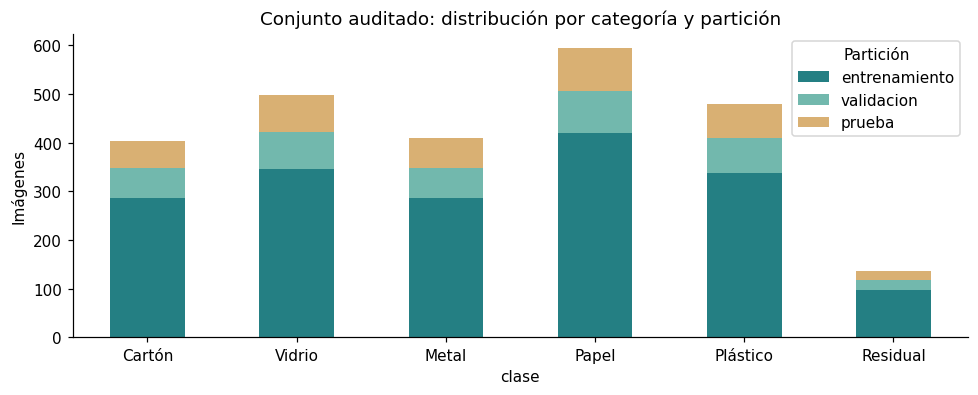

In [10]:
checks = {
    "Conteos originales coinciden con la fuente": counts.to_dict() == EXPECTED,
    "Todas las imágenes se decodifican": len(valid) == len(raw),
    "Sin rutas repetidas": raw["ruta"].is_unique,
    "Seis categorías esperadas": set(usable["clase"]) == set(CLASSES),
    "Sin píxeles idénticos repetidos en datos utilizables": usable["pixel_sha256"].is_unique,
    "Conflictos exactos apartados": not usable["pixel_sha256"].isin(conflict_hashes).any(),
    "Cada grupo pertenece a una sola partición": usable.groupby("grupo")["particion"].nunique().max() == 1,
    "Cada imagen tiene pliegue asignado": usable["pliegue"].ge(0).all(),
    "Todas las categorías están en las tres particiones": split_table.gt(0).all().all(),
    "Las particiones cubren el conjunto utilizable": int(split_table.to_numpy().sum()) == len(usable),
}
check_table = pd.DataFrame({"control": checks.keys(),
                            "resultado": ["OK" if flag else "REVISAR" for flag in checks.values()]})
display(check_table)
assert all(checks.values()), "Un control falló: revise los resultados antes del modelado."

ax = split_table.rename(index=LABEL_ES).plot.bar(
    stacked=True, figsize=(9, 3.7), color=["#247f83", "#72b8ad", "#d9b073"], rot=0)
ax.set(title="Conjunto auditado: distribución por categoría y partición", ylabel="Imágenes")
ax.legend(title="Partición", loc="upper right")
plt.tight_layout()
plt.show()

## 11. Registro y trazabilidad

La siguiente celda genera archivos auxiliares reproducibles dentro de la sesión: inventario original, conflictos, candidatos similares, manifiesto para modelado y resumen de auditoría. No es necesario entregarlos por separado: sus resultados y el código que los regenera están en este notebook. Las rutas de las imágenes son relativas para que el manifiesto pueda reutilizarse en Colab.

In [11]:
raw.to_csv(REPORT_DIR / "inventario_original.csv", index=False)
conflicts.to_csv(REPORT_DIR / "conflictos_etiqueta.csv", index=False)
similar.to_csv(REPORT_DIR / "candidatos_similares.csv", index=False)
usable.to_csv(REPORT_DIR / "manifiesto_modelado.csv", index=False)

summary = {
    "ejecutado_utc": datetime.now(timezone.utc).isoformat(),
    "fuente": DATA_URL, "revision": REVISION,
    "zip_sha256": sha256_file(ARCHIVE), "zip_bytes": ARCHIVE.stat().st_size,
    "semilla": SEED, "versiones": versions,
    "imagenes_originales": len(raw), "imagenes_legibles": len(valid),
    "copias_exactas_adicionales": int(valid["sha256"].duplicated().sum()),
    "grupos_conflictivos": len(conflict_hashes), "archivos_conflictivos": len(conflicts),
    "umbral_phash": PHASH_THRESHOLD, "pares_candidatos_originales": len(similar),
    "imagenes_utilizables": len(usable), "grupos_modelado": int(usable["grupo"].nunique()),
    "conteos_originales": {key: int(value) for key, value in counts.items()},
    "conteos_particiones": {key: int(value) for key, value in usable["particion"].value_counts().items()},
    "controles": {key: bool(value) for key, value in checks.items()},
}
(REPORT_DIR / "resumen_auditoria.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print("Reportes generados en residuos_fase1/reportes:")
for path in sorted(REPORT_DIR.iterdir()):
    print("•", path.name)

Reportes generados en residuos_fase1/reportes:
• candidatos_similares.csv
• conflictos_etiqueta.csv
• inventario_original.csv
• manifiesto_modelado.csv
• resumen_auditoria.json


## 12. Metodología prevista para las fases siguientes

**Pregunta experimental:** ¿la transferencia de aprendizaje mejora la clasificación de residuos respecto de una CNN pequeña entrenada desde cero, usando el mismo conjunto auditado y el mismo protocolo de evaluación?

La transferencia reutiliza representaciones aprendidas y entrena una nueva salida adaptada a la tarea [7–8]. Es una opción razonable ante un dataset pequeño, pero su ventaja en este experimento deberá comprobarse.

| Elemento | Decisión inicial |
|---|---|
| Referencia mínima | Predecir siempre la categoría más frecuente de entrenamiento; reportar sus métricas en validación y prueba |
| Modelo A | CNN con tres bloques convolucionales pequeños, agrupación espacial y salida softmax de seis clases |
| Modelo B | MobileNetV2 con pesos de ImageNet; extractor inicialmente congelado y nueva salida de seis clases |
| Entrada | RGB de 160 × 160; mantener el criterio de redimensionado y padding documentado para ambos modelos |
| Escala | CNN: píxeles en [0,1]. MobileNetV2: preprocesamiento propio; evitar aplicar dos normalizaciones |
| Aumentos | Giros moderados y reflexión horizontal solamente en entrenamiento; revisar que preserven la etiqueta |
| Desbalance | Evaluar pesos por clase calculados solo con entrenamiento y documentar su efecto en validación |
| Entrenamiento inicial | Hasta 20 épocas para CNN y 15 para la nueva cabeza; parada temprana con paciencia 3 y mejor estado restaurado |
| Extensión opcional | Ajuste de últimas capas de MobileNetV2, si queda presupuesto y la validación lo justifica |
| Comparación | Mismas particiones, mismos ejemplos de evaluación y configuraciones registradas |
| Métrica principal | F1 macro: promedio no ponderado del F1 de cada clase |
| Métricas complementarias | Precision, recall y F1 por clase, accuracy, matriz de confusión, tiempo de entrenamiento e inferencia |

**Reglas de evaluación.** Se usa validación para escoger modelos y ajustes. La prueba se consulta una vez fijadas ambas configuraciones. Los tiempos se acompañarán del hardware y del tamaño de lote; no se asumirán tiempos de entrenamiento antes de medirlos. El tamaño pequeño de la categoría residual en prueba se hará explícito al interpretar sus métricas. Si se calculan intervalos por remuestreo, se respetarán los grupos de similitud.

**Análisis de errores.** Revisar confusiones entre materiales, fondos, iluminación, objetos compuestos y categoría residual. Una buena métrica dentro de TrashNet no demuestra desempeño en escenas urbanas, otros dispositivos o residuos mezclados. La demostración final deberá comunicar ese dominio de aplicación.

**Decisión al cierre.** Si el modelo alcanza las metas y sus errores son aceptables para una actividad educativa supervisada, proponer un piloto con imágenes externas y un protocolo de medición de utilidad. Si no las alcanza, documentar qué clases o condiciones requieren datos adicionales. La comparación y las conclusiones se conservarán en ambos casos.

## 13. Conclusiones de la fase 1

Las conclusiones siguientes se construyen a partir de las variables calculadas en esta ejecución. No contienen resultados predictivos ni beneficios operacionales simulados.

In [12]:
sizes = usable["particion"].value_counts()
display(Markdown(
    f"1. **Acceso y cantidad verificados:** {miles(len(raw))} imágenes descargadas de una revisión fija; "
    f"{miles(len(valid))} se decodifican y los conteos por clase coinciden con la fuente.\n"
    f"2. **Hallazgo de calidad:** {len(conflict_hashes)} pares de contenido idéntico tienen etiquetas "
    f"distintas. Se apartaron sus {len(conflicts)} archivos y quedaron **{miles(len(usable))} imágenes** "
    "para el experimento.\n"
    f"3. **Control de similitud:** se identificaron {len(similar)} pares candidatos en el conjunto "
    "original. Los candidatos conservados se agruparon antes de la partición; no se reinterpretaron "
    "como duplicados confirmados.\n"
    f"4. **Partición preparada:** {miles(sizes['entrenamiento'])} imágenes de entrenamiento, "
    f"{miles(sizes['validacion'])} de validación y {miles(sizes['prueba'])} de prueba. "
    "No hay cruces entre particiones de los grupos definidos por la auditoría.\n"
    "5. **Viabilidad condicionada al alcance:** el volumen permite abordar una comparación acotada "
    "de dos modelos. El desbalance, los fondos controlados y la falta de identificadores de objeto "
    "siguen siendo limitaciones explícitas.\n"
    "6. **Siguiente hito:** implementar el preprocesamiento y el primer modelo, conservar estas "
    "particiones y medir el costo real de ejecución antes de ampliar los experimentos."
))

1. **Acceso y cantidad verificados:** 2.527 imágenes descargadas de una revisión fija; 2.527 se decodifican y los conteos por clase coinciden con la fuente.
2. **Hallazgo de calidad:** 3 pares de contenido idéntico tienen etiquetas distintas. Se apartaron sus 6 archivos y quedaron **2.521 imágenes** para el experimento.
3. **Control de similitud:** se identificaron 28 pares candidatos en el conjunto original. Los candidatos conservados se agruparon antes de la partición; no se reinterpretaron como duplicados confirmados.
4. **Partición preparada:** 1.772 imágenes de entrenamiento, 375 de validación y 374 de prueba. No hay cruces entre particiones de los grupos definidos por la auditoría.
5. **Viabilidad condicionada al alcance:** el volumen permite abordar una comparación acotada de dos modelos. El desbalance, los fondos controlados y la falta de identificadores de objeto siguen siendo limitaciones explícitas.
6. **Siguiente hito:** implementar el preprocesamiento y el primer modelo, conservar estas particiones y medir el costo real de ejecución antes de ampliar los experimentos.

## 14. Referencias

Fuentes consultadas para la propuesta el 13 de octubre de 2026. Los conteos de auditoría se calculan en el notebook; los tamaños de las alternativas provienen de sus fichas.

1. Thung, G. y Yang, M. *TrashNet: repositorio y descripción del conjunto de datos*. [GitHub](https://github.com/garythung/trashnet).
2. Thung, G. *TrashNet: distribución del autor, versión reducida y licencia declarada*. [Revisión fijada en Hugging Face](https://huggingface.co/datasets/garythung/trashnet/tree/94cd17ebfd6702bf62281d3c89f22ff649815b46).
3. UNEP e ISWA (2024). *Global Waste Management Outlook 2024*. [Informe y hallazgos](https://www.unep.org/en/publications/report/global-waste-management-outlook-2024).
4. TensorFlow Datasets / Makerere AI Lab. *Beans*. [Ficha del dataset](https://www.tensorflow.org/datasets/catalog/beans).
5. PolyAI. *BANKING77*. [Repositorio original](https://github.com/PolyAI-LDN/task-specific-datasets) y [ficha del autor](https://huggingface.co/datasets/PolyAI/banking77).
6. Almeida, T. y Hidalgo, J. (2011). *SMS Spam Collection*. [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
7. TensorFlow. *Transfer learning and fine-tuning*. [Guía oficial](https://www.tensorflow.org/tutorials/images/transfer_learning).
8. Keras. *Transfer learning & fine-tuning*. [Guía oficial](https://keras.io/guides/transfer_learning/).
9. Google. *Preguntas frecuentes de Colab*. [Recursos y disponibilidad](https://research.google.com/colaboratory/intl/es/faq.html).
10. Material de la actividad en la plataforma del curso: *Presentación del proyecto aplicado* e *Instrucciones de Proyecto aplicado - Fase 1*. El notebook guía es opcional; se utiliza una estructura propia, permitida por las instrucciones.